# 02. 비트 변화가 전력으로 보이는 이유

01번에서는 파형 차이로 비밀번호를 찾았습니다. 이제 MCU 내부 값과 전력 소비를 연결하는 Hamming weight와 Hamming distance를 살펴보고, 실제 TVLA로 누설 위치를 찾겠습니다.

## Hamming weight

Hamming weight는 비트열에서 1의 개수입니다. 파형 배열이 `float32`인 것은 ADC 값을 소수로 저장했기 때문이며, 누설 모델의 Hamming weight와는 별개입니다.

0x3A = 00111010
Hamming weight = 4


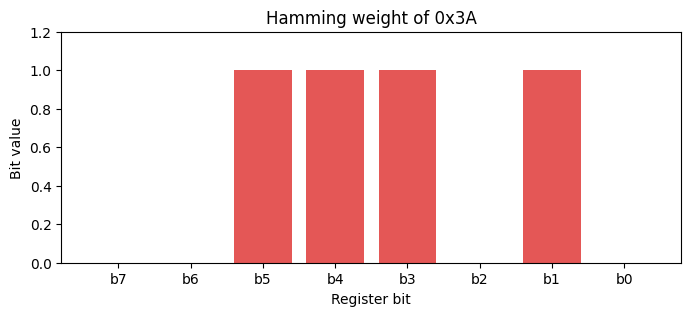

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from cw_sca_tutorial.analysis import welch_t_test
from cw_sca_tutorial.demo import demo_run

value = 0x3A
bits = np.array([(value >> bit) & 1 for bit in range(7, -1, -1)])
print(f"0x{value:02X} = {value:08b}")
print("Hamming weight =", value.bit_count())

plt.figure(figsize=(8, 3))
plt.bar(range(8), bits, color=np.where(bits, "#e45756", "#d9d9d9"))
plt.xticks(range(8), [f"b{bit}" for bit in range(7, -1, -1)])
plt.ylim(0, 1.2)
plt.xlabel("Register bit")
plt.ylabel("Bit value")
plt.title("Hamming weight of 0x3A")
plt.show()

## Hamming distance

Hamming distance는 이전 값과 새 값 사이에서 바뀐 비트 수입니다. 실제 CMOS 동적 전력은 충전·방전된 노드 수와 관련되므로 Hamming distance가 더 자연스러운 모델인 경우도 많습니다.

In [2]:
old = 0x00
new = 0xFF
distance = (old ^ new).bit_count()

print(f"old : {old:08b}")
print(f"new : {new:08b}")
print(f"xor : {old ^ new:08b}")
print("Hamming distance =", distance)

old : 00000000
new : 11111111
xor : 11111111
Hamming distance = 8


## 실제 fixed-vs-random 데이터

AES 키는 고정한 채 평문이 항상 같은 그룹 500개와 매번 달라지는 그룹 500개를 측정했습니다. 두 그룹은 시간 순서에 따른 드리프트가 한쪽에 몰리지 않도록 섞어서 수집했습니다.

In [3]:
import json

run = demo_run("aes_tvla")
metadata = json.loads((run / "metadata.json").read_text())
data = np.load(run / "traces.npz")
traces = data["traces"]
groups = data["groups"]
fixed = traces[groups == 0]
random = traces[groups == 1]

print("DATA SOURCE : MEASURED")
print("RUN         :", run.name)
print("TARGET      :", metadata["target_identity"]["user_identification"])
print(f"GROUPS      : fixed={len(fixed)}, random={len(random)}")

DATA SOURCE : MEASURED
RUN         : 20261022T125656Z-aes-tvla
TARGET      : STM32F303
GROUPS      : fixed=500, random=500


## 평균 파형과 Welch t-test

평균 파형 두 개는 비슷해 보이지만 샘플별 Welch t-test를 계산하면 반복되는 작은 차이가 드러납니다. 빨간 점선은 수업에서 자주 사용하는 `±4.5` 기준입니다.

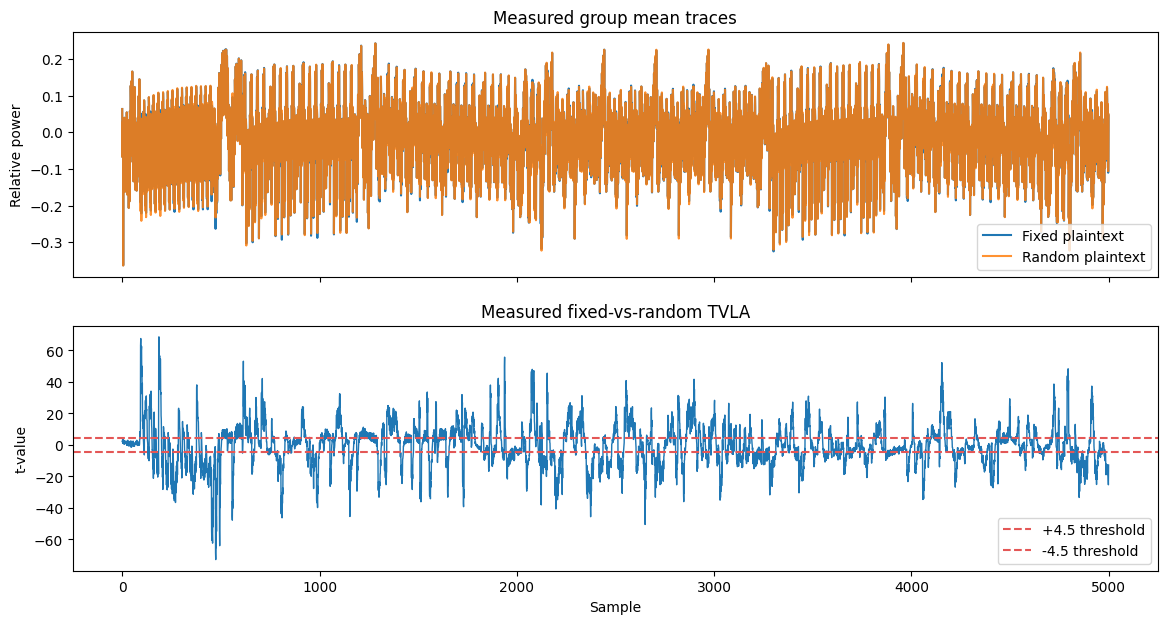

maximum |t| = 72.80 at sample 474
comparison window 0:50 maximum |t| = 3.79


In [4]:
t_values = welch_t_test(traces, groups)
threshold = 4.5
peak = int(np.argmax(np.abs(t_values)))

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(fixed.mean(axis=0), label="Fixed plaintext")
axes[0].plot(random.mean(axis=0), label="Random plaintext", alpha=.85)
axes[0].set(title="Measured group mean traces", ylabel="Relative power")
axes[0].legend()
axes[1].plot(t_values, linewidth=1)
axes[1].axhline(threshold, color="#e45756", linestyle="--", label="+4.5 threshold")
axes[1].axhline(-threshold, color="#e45756", linestyle="--", label="-4.5 threshold")
axes[1].set(title="Measured fixed-vs-random TVLA", xlabel="Sample", ylabel="t-value")
axes[1].legend()
plt.show()

print(f"maximum |t| = {abs(t_values[peak]):.2f} at sample {peak}")
print(f"comparison window 0:50 maximum |t| = {np.max(np.abs(t_values[:50])):.2f}")
assert np.max(np.abs(t_values)) > threshold

## 파형 수를 늘리면

각 그룹에서 사용하는 파형 수를 늘리며 최대 `|t|`를 다시 계산합니다. TVLA는 누설 위치를 찾는 검사이며, 이 단계에서는 아직 키 후보를 사용하지 않습니다.

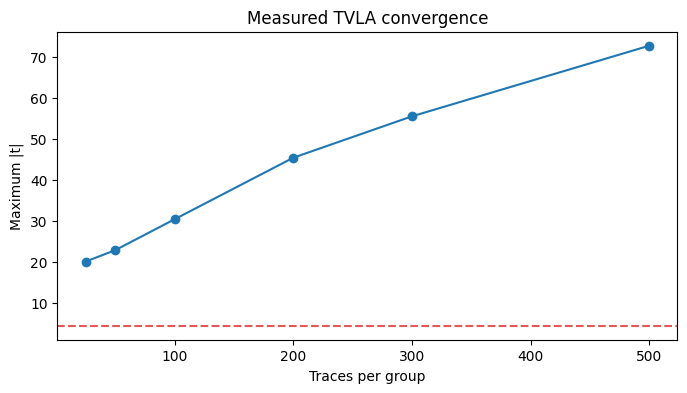

In [5]:
counts = [25, 50, 100, 200, 300, 500]
max_t = []
for count in counts:
    subset = np.concatenate([
        np.flatnonzero(groups == 0)[:count],
        np.flatnonzero(groups == 1)[:count],
    ])
    max_t.append(float(np.max(np.abs(welch_t_test(traces[subset], groups[subset])))))

plt.figure(figsize=(8, 4))
plt.plot(counts, max_t, "o-")
plt.axhline(4.5, color="#e45756", linestyle="--")
plt.xlabel("Traces per group")
plt.ylabel("Maximum |t|")
plt.title("Measured TVLA convergence")
plt.show()